In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, event, text
from sqlalchemy.engine import URL

ROOT = r'D:\Bluestock work\bluestock-fintech-analysis1'
PROCESSED_DIR = os.path.join(ROOT, 'data', 'processed')
REPORTS_DIR = os.path.join(ROOT, 'reports')
DB_PATH = os.path.join(PROCESSED_DIR, 'bluestock_dw.db')

engine = create_engine(URL.create('sqlite', database=DB_PATH))

@event.listens_for(engine, 'connect')
def turn_on_foreign_keys(dbapi_connection, connection_record):
    cursor = dbapi_connection.cursor()
    cursor.execute('PRAGMA foreign_keys = ON')
    cursor.close()

In [3]:
bounds = pd.read_sql_query("""
SELECT n.amfi_code,
       MIN(d.full_date) AS first_date,
       MAX(d.full_date) AS last_date,
       COUNT(*)         AS nav_rows
FROM fact_nav AS n
JOIN dim_date AS d ON d.date_key = n.date_key
GROUP BY n.amfi_code
""", engine)

bounds['first_date'] = pd.to_datetime(bounds['first_date'])
bounds['last_date'] = pd.to_datetime(bounds['last_date'])

END_DATE = bounds['last_date'].max()

print('Funds:', len(bounds))
print('End date:', END_DATE.date())
print('Oldest first date:', bounds['first_date'].min().date(), '| newest first date:', bounds['first_date'].max().date())

stale = bounds[bounds['last_date'] < END_DATE]
print('Funds whose last NAV is before the end date:', len(stale)) 

Funds: 40
End date: 2026-05-29
Oldest first date: 2022-01-03 | newest first date: 2022-01-03
Funds whose last NAV is before the end date: 0


In [4]:
nav = pd.read_sql_query("""
SELECT n.amfi_code, d.full_date, n.nav, n.is_filled
FROM fact_nav AS n
JOIN dim_date AS d ON d.date_key = n.date_key
""", engine)

nav['date'] = pd.to_datetime(nav['full_date'])

nav_wide = nav.pivot(index='date', columns='amfi_code', values='nav').sort_index()
filled_wide = nav.pivot(index='date', columns='amfi_code', values='is_filled').sort_index()

print(nav_wide.shape)
print(nav_wide.index.min().date(), 'to', nav_wide.index.max().date())

(1608, 40)
2022-01-03 to 2026-05-29


In [5]:
def nav_on(date):
    return nav_wide.reindex([date]).iloc[0]


def filled_on(date):
    return filled_wide.reindex([date]).iloc[0]


nav_end = nav_on(END_DATE)

start_dates = {}
for n in [1, 3, 5]:
    start_dates[n] = END_DATE - pd.DateOffset(years=n)
    print(n, 'year start date:', start_dates[n].date(), '| weekday:', start_dates[n].day_name())

print('Funds with an end NAV:', nav_end.notnull().sum())

1 year start date: 2025-05-29 | weekday: Thursday
3 year start date: 2023-05-29 | weekday: Monday
5 year start date: 2021-05-29 | weekday: Saturday
Funds with an end NAV: 40


In [6]:
results = pd.DataFrame(index=nav_wide.columns)
results.index.name = 'amfi_code'
results['nav_end'] = nav_end

for n in [1, 3, 5]:
    nav_start = nav_on(start_dates[n])
    results[f'nav_start_{n}yr'] = nav_start
    results[f'total_{n}yr_pct'] = (nav_end / nav_start - 1) * 100
    results[f'cagr_{n}yr_pct'] = ((nav_end / nav_start) ** (1 / n) - 1) * 100

for n in [1, 3, 5]:
    print(n, 'year: funds with a CAGR:', results[f'cagr_{n}yr_pct'].notnull().sum(), 'of', len(results))

results[['cagr_1yr_pct', 'cagr_3yr_pct', 'cagr_5yr_pct']].describe().round(2)

1 year: funds with a CAGR: 40 of 40
3 year: funds with a CAGR: 40 of 40
5 year: funds with a CAGR: 0 of 40


,cagr_1yr_pct,cagr_3yr_pct,cagr_5yr_pct
count,40.00,40.00,0.0
mean,19.43,16.41,NaN
std,22.91,12.21,NaN
min,-42.80,-11.71,NaN
25%,7.38,6.60,NaN
50%,17.47,18.23,NaN
75%,27.16,26.90,NaN
max,82.78,35.11,NaN


In [7]:
# Check A
same = np.allclose(results['cagr_1yr_pct'], results['total_1yr_pct'], equal_nan=True)
print('A. 1-year CAGR equals 1-year total return:', same)

# Check B
for n in [1, 3, 5]:
    values = results[f'cagr_{n}yr_pct'].dropna()
    print(f'B. {n}-year CAGR above -100 for all funds:', bool((values > -100).all()))

# Check C
code = int(results['cagr_3yr_pct'].dropna().index[0])
start_key = int(start_dates[3].strftime('%Y%m%d'))
end_key = int(END_DATE.strftime('%Y%m%d'))

spot = pd.read_sql_query(
    text('SELECT date_key, nav FROM fact_nav WHERE amfi_code = :code AND date_key IN (:a, :b)'),
    engine, params={'code': code, 'a': start_key, 'b': end_key})

nav_s = spot.loc[spot['date_key'] == start_key, 'nav'].iloc[0]
nav_e = spot.loc[spot['date_key'] == end_key, 'nav'].iloc[0]
manual = ((nav_e / nav_s) ** (1 / 3) - 1) * 100

print('C. Fund', code, '| by hand:', round(manual, 4), '| in the table:', round(results.loc[code, 'cagr_3yr_pct'], 4))
print('C. Same value:', np.isclose(manual, results.loc[code, 'cagr_3yr_pct']))

A. 1-year CAGR equals 1-year total return: True
B. 1-year CAGR above -100 for all funds: True
B. 3-year CAGR above -100 for all funds: True
B. 5-year CAGR above -100 for all funds: True
C. Fund 100016 | by hand: 1.2926 | in the table: 1.2926
C. Same value: True


In [10]:
funds = pd.read_sql_query(
    'SELECT amfi_code, scheme_name, fund_house, category, plan FROM dim_fund', engine)

table = results.reset_index().merge(funds, on='amfi_code', how='left')
table = table.merge(bounds[['amfi_code', 'first_date', 'last_date']], on='amfi_code', how='left')

table['history_years'] = ((END_DATE - table['first_date']).dt.days / 365.25).round(1)
table['is_idcw'] = table['scheme_name'].str.contains('IDCW|Dividend', case=False, na=False)
table['end_is_filled'] = table['amfi_code'].map(filled_on(END_DATE)).fillna(0).astype(int)

for n in [1, 3, 5]:
    table[f'rank_{n}yr'] = table[f'cagr_{n}yr_pct'].rank(ascending=False, method='min')
    table[f'rank_{n}yr_in_category'] = (
        table.groupby('category')[f'cagr_{n}yr_pct'].rank(ascending=False, method='min'))

show_cols = ['amfi_code', 'scheme_name', 'category', 'plan',
             'cagr_1yr_pct', 'cagr_3yr_pct', 'cagr_5yr_pct',
             'rank_3yr', 'rank_3yr_in_category', 'history_years', 'is_idcw']

comparison = table[show_cols].sort_values('cagr_3yr_pct', ascending=False).round(2)

print('IDCW funds:', table['is_idcw'].sum())
print('End NAV copied from an earlier day:', table['end_is_filled'].sum())
print(comparison.to_string(index=False))

IDCW funds: 0
End NAV copied from an earlier day: 0
 amfi_code                                           scheme_name category    plan  cagr_1yr_pct  cagr_3yr_pct  cagr_5yr_pct  rank_3yr  rank_3yr_in_category  history_years  is_idcw
    119094                   Axis Midcap Fund - Regular - Growth   Equity Regular         22.26         35.11           NaN       1.0                   1.0            4.4    False
    148567         Mirae Asset Large Cap Fund - Regular - Growth   Equity Regular         20.36         34.00           NaN       2.0                   2.0            4.4    False
    120504             ICICI Pru Bluechip Fund - Direct - Growth   Equity  Direct         13.06         32.49           NaN       3.0                   3.0            4.4    False
    100033    HDFC Mid-Cap Opportunities Fund - Regular - Growth   Equity Regular         53.23         32.44           NaN       4.0                   4.0            4.4    False
    120505              ICICI Pru Midcap Fund - 

In [11]:
perf = pd.read_sql_query(
    'SELECT amfi_code, return_1yr_pct, return_3yr_pct, return_5yr_pct FROM fact_performance', engine)

cmp = table.merge(perf, on='amfi_code', how='inner')

for n in [1, 3, 5]:
    diff_cagr = (cmp[f'cagr_{n}yr_pct'] - cmp[f'return_{n}yr_pct']).abs()
    diff_total = (cmp[f'total_{n}yr_pct'] - cmp[f'return_{n}yr_pct']).abs()
    corr = cmp[[f'cagr_{n}yr_pct', f'return_{n}yr_pct']].corr().iloc[0, 1]
    print(f'{n} year | mean difference vs my CAGR: {diff_cagr.mean():.2f}'
          f' | vs my total return: {diff_total.mean():.2f} | correlation: {corr:.2f}')

1 year | mean difference vs my CAGR: 15.73 | vs my total return: 15.73 | correlation: 0.11
3 year | mean difference vs my CAGR: 10.17 | vs my total return: 56.33 | correlation: 0.08
5 year | mean difference vs my CAGR: nan | vs my total return: nan | correlation: nan


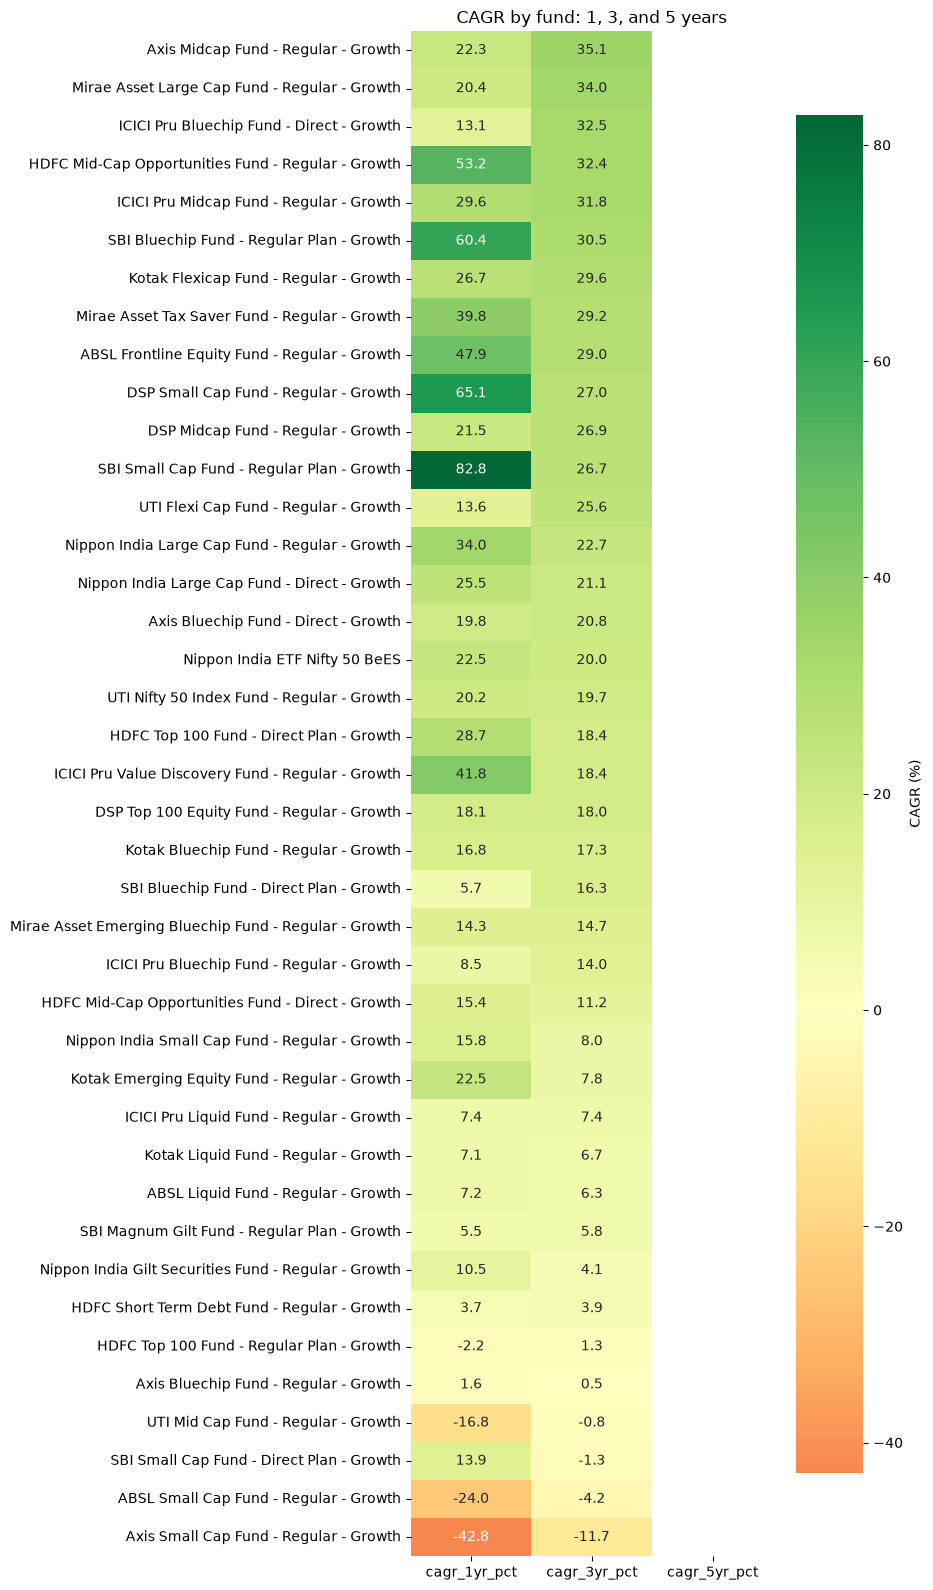

In [12]:
heat = table.set_index('scheme_name')[['cagr_1yr_pct', 'cagr_3yr_pct', 'cagr_5yr_pct']]
heat = heat.sort_values('cagr_3yr_pct', ascending=False)

plt.figure(figsize=(9, 16))
sns.heatmap(heat, annot=True, fmt='.1f', cmap='RdYlGn', center=0,
            cbar_kws={'label': 'CAGR (%)'})
plt.title('CAGR by fund: 1, 3, and 5 years')
plt.ylabel('')
plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'cagr_heatmap.png'))
plt.show()

In [14]:
table_out = table[show_cols + ['cagr_1yr_pct', 'total_1yr_pct', 'total_3yr_pct', 'total_5yr_pct']].copy()
table_out = table_out.loc[:, ~table_out.columns.duplicated()].round(4)
table_out.to_csv(os.path.join(PROCESSED_DIR, 'fund_cagr_comparison.csv'), index=False)

best = table.nlargest(3, 'cagr_3yr_pct')['scheme_name'].tolist()
worst = table.nsmallest(3, 'cagr_3yr_pct')['scheme_name'].tolist()

lines = [
    '# CAGR summary',
    '',
    f'- Formula: CAGR = (NAV_end / NAV_start) ^ (1 / n) - 1, for n = 1, 3, and 5 years. Shown in percent.',
    f'- End date: {END_DATE.date()}. Start dates: ' + ', '.join(f'{n} yr {start_dates[n].date()}' for n in [1, 3, 5]) + '.',
    '- NAV on a weekend or holiday is the last known NAV (filled rows from Task 8).',
    f'- Funds: {len(table)}. With a CAGR: 1 yr {table["cagr_1yr_pct"].notnull().sum()}, 3 yr {table["cagr_3yr_pct"].notnull().sum()}, 5 yr {table["cagr_5yr_pct"].notnull().sum()}. The others have too little history or a NAV gap.',
    f'- Best 3-year CAGR: {best}.',
    f'- Worst 3-year CAGR: {worst}.',
    f'- IDCW funds (CAGR from NAV is too low for these): {int(table["is_idcw"].sum())}.',
    f'- Funds whose last NAV is before the end date: {len(stale)}.',
    '- Checks passed: 1-year CAGR equals the total return, CAGR above -100, spot check with SQL.',
    '- Comparison with the source returns in fact_performance: see the notebook, Step 8.',
    '',
    '## Assumptions to confirm',
    '- The end date is the newest NAV date in the data.',
    '- n is a whole number of calendar years.',
    '- CAGR uses two NAV values only. It depends on the start and end dates.',
]

summary_text = '\n'.join(lines)

with open(os.path.join(REPORTS_DIR, 'cagr_summary.md'), 'w', encoding='utf-8') as f:
    f.write(summary_text)

print(summary_text)

# CAGR summary

- Formula: CAGR = (NAV_end / NAV_start) ^ (1 / n) - 1, for n = 1, 3, and 5 years. Shown in percent.
- End date: 2026-05-29. Start dates: 1 yr 2025-05-29, 3 yr 2023-05-29, 5 yr 2021-05-29.
- NAV on a weekend or holiday is the last known NAV (filled rows from Task 8).
- Funds: 40. With a CAGR: 1 yr 40, 3 yr 40, 5 yr 0. The others have too little history or a NAV gap.
- Best 3-year CAGR: ['Axis Midcap Fund - Regular - Growth', 'Mirae Asset Large Cap Fund - Regular - Growth', 'ICICI Pru Bluechip Fund - Direct - Growth'].
- Worst 3-year CAGR: ['Axis Small Cap Fund - Regular - Growth', 'ABSL Small Cap Fund - Regular - Growth', 'SBI Small Cap Fund - Direct Plan - Growth'].
- IDCW funds (CAGR from NAV is too low for these): 0.
- Funds whose last NAV is before the end date: 0.
- Checks passed: 1-year CAGR equals the total return, CAGR above -100, spot check with SQL.
- Comparison with the source returns in fact_performance: see the notebook, Step 8.

## Assumptions to confirm
- 